## KNN: ImageNet

Load default ResNet50 trained on ImageNet and predict concepts for several classes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import glob, os, cv2, pickle
from sklearn.metrics import label_ranking_average_precision_score as lrap
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.metrics.pairwise import cosine_similarity
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D

In [2]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2024-03-13 15:01:27.832121: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-03-13 15:01:28.379432: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [3]:
IMAGES_PATH = '../data/Unsplash/images/'
BRODEN_PATH = '../data/broden1_224/images/dtd/' # texture images (path used only when first saving broden images to subfolder in Unsplash)
CONCEPTS_PATH = '../data/Unsplash/concepts_stab/'
LOAD_NEW_BRODEN = False
concepts = ['chequered', 'dotted', 'striped']
img_height = img_width = 224

### Load Test Images

In [4]:
classes = [c.split('/')[-1] for c in sorted(glob.glob(IMAGES_PATH + '*'))]
classes

['cheetah', 'snake', 'tiger', 'turtle', 'zebra']

In [5]:
test_set = tf.keras.utils.image_dataset_from_directory(
    IMAGES_PATH,
    shuffle=False,
    seed=123,
    image_size=(img_height, img_width),
    batch_size=None)

Found 212 files belonging to 5 classes.


2024-03-13 15:01:28.442676: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [6]:
# Preprocess raw images (required by resnet initialized with imagenet weights)
test_set = test_set.map(lambda x, y: (tf.keras.applications.resnet50.preprocess_input(x), y))

In [7]:
# Get concept label vector from tf.Dataset
y_true_img = np.asarray([lab.numpy() for _, lab in test_set])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


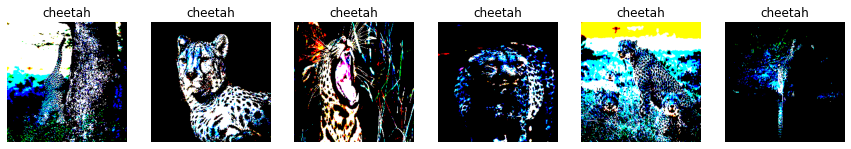

In [8]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = 6
with tf.device('/CPU:0'):
    i=0
    for img, lab in test_set.take(num_cols):
        plt.subplot(1, num_cols, i + 1)
        plt.imshow(img)
        plt.title(classes[lab.numpy()])
        plt.axis("off")
        i+=1
plt.show()

### Load Concept Images

Loading and preprocessing of broden data copied from https://colab.research.google.com/drive/1iuEz46ZjgG97vTBH8p-vod3y14UETvVE#scrollTo=5oT_JAvEgjhv

In [9]:
def central_crop_and_resize(img, input_size):
  h, w, _ = img.shape
  min_side = min(h, w)
  max_side_center = max(h, w) // 2.0
  min_cut = int(max_side_center-min_side//2)
  max_cut = int(max_side_center+min_side//2)
  img = img[:, min_cut:max_cut] if w > h else img[min_cut:max_cut]
  img = tf.image.resize(img, (input_size, input_size)).numpy()
  return img

def load_texture(texture):
  files = [BRODEN_PATH + t for t in textures_files if texture in t]
  imgs  = [cv2.imread(img)[...,::-1] for img in files]
  imgs  = [central_crop_and_resize(img, img_height) for img in imgs]
  imgs  = [np.array(img, np.float32) for img in imgs if img.max() > 250]
  imgs  = np.array(imgs)
  return imgs

In [10]:
if LOAD_NEW_BRODEN:
    textures_files = os.listdir(BRODEN_PATH)
    textures = {texture: load_texture(texture) for texture in concepts}

    for texture_name, images in textures.items():

        for i in range(30):
            plt.imshow(images[i] / 255.0)
            plt.axis('off')
            plt.savefig(CONCEPTS_PATH + texture_name + '/' + str(i) + '.jpg', bbox_inches='tight')
        plt.show()

In [11]:
concept_set = tf.keras.utils.image_dataset_from_directory(
    CONCEPTS_PATH,
    shuffle=False,
    seed=123,
    image_size=(img_height, img_width),
    batch_size=None)

Found 76 files belonging to 3 classes.


In [12]:
# Preprocess raw images (required by resnet initialized with imagenet weights)
concept_set = concept_set.map(lambda x, y: (tf.keras.applications.resnet50.preprocess_input(x), y))

In [13]:
# Get concept label vector from tf.Dataset
y_true_con = np.asarray([lab.numpy() for _, lab in concept_set])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


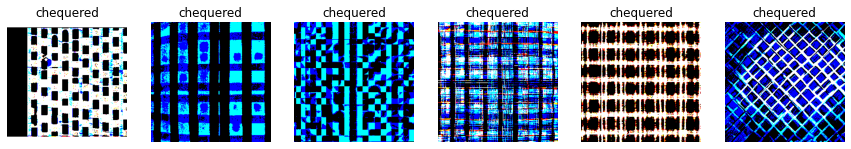

In [14]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = 6
with tf.device('/CPU:0'):
    i=0
    for img, lab in concept_set.take(num_cols):
        plt.subplot(1, num_cols, i + 1)
        plt.imshow(img)
        plt.title(concepts[lab.numpy()])
        plt.axis("off")
        i+=1
plt.show()

### Load Random Images

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

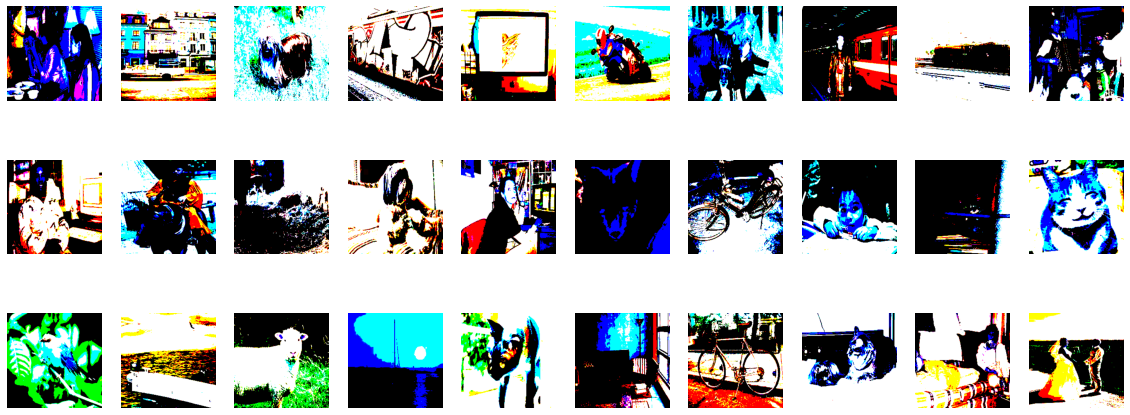

In [15]:
random_img_folder = '../data/broden1_224/images/pascal/'
input_size = img_height

random_imgs = os.listdir(random_img_folder)
random_imgs_filter = lambda f : all([rm not in f for rm in ['object', 'color', 'part']]) # only take 'natural' image

# Load same random images used for tcav fungi
with open('./beexplainable/metafiles/Fungi/raw/fungi_tcav_random.pickle', 'rb') as handle:
    files = pickle.load(handle)

random_dataset = [cv2.imread(random_img_folder+img)[...,::-1] for img in files]
random_dataset = [tf.image.resize(img, [img_width, img_height]) for img in random_dataset]
random_dataset = np.array([tf.keras.applications.resnet50.preprocess_input(img) for img in random_dataset])

plt.figure(figsize = (20, 8))
for i in range(30):
    plt.subplot(3, 10, i+1)
    plt.imshow(random_dataset[i])
    plt.axis('off')

### Predict Concepts

In [16]:
# Load ResNet backbone
base_model = ResNet50(input_shape=(img_height, img_width, 3), weights='imagenet', include_top=False)

In [17]:
# Extract features of concept images with ResNet backbone
res_concepts = base_model.predict(concept_set.batch(32))
res_concepts = GlobalAveragePooling2D()(res_concepts)
tf.shape(res_concepts)

2024-03-13 15:01:37.146737: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2024-03-13 15:01:37.629593: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-13 15:01:37.630614: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-13 15:01:37.630626: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-03-13 15:01:37.631704: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-13 15:01:37.631743: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


<tf.Tensor: shape=(2,), dtype=int32, numpy=array([  76, 2048], dtype=int32)>

In [18]:
con_rand_set = []
for img, _ in concept_set.as_numpy_iterator():
    con_rand_set.append(img)
con_rand_set = np.asarray(con_rand_set)
con_rand_set = np.concatenate((con_rand_set, random_dataset))
print(con_rand_set.shape)

y_true_con_rand = np.concatenate((y_true_con, np.array([len(concepts)]*len(random_dataset))))
print(y_true_con_rand.shape)

(1076, 224, 224, 3)
(1076,)


In [19]:
res_con_rand = base_model.predict(con_rand_set)
res_con_rand = GlobalAveragePooling2D()(res_con_rand)
tf.shape(res_con_rand)

<tf.Tensor: shape=(2,), dtype=int32, numpy=array([1076, 2048], dtype=int32)>

In [20]:
# Extract features for all samples
test_activations = GlobalAveragePooling2D()(base_model.predict(test_set.batch(32)))
test_activations.shape

TensorShape([212, 2048])

#### Multiple random partitions, one kNN for all concepts

In [21]:
# One-hot-encode the concepts
concept_basis = OneHotEncoder().fit_transform([[0], [1], [2]]).toarray()
lookup_cls_concepts = [concept_basis[1], # cheetah -> dotted
                       concept_basis[0], # snake -> chequered
                       concept_basis[2], # tiger -> striped
                       concept_basis[0], # turtle -> chequered
                       concept_basis[2]] # zebra -> striped

In [22]:
# Fit multiple kNNs for multiple random partitions of the random set
k = 36 # optimal k found in ...optim_k.ipynb
num_parts = 100 # how often to randomly select subsets of the random set
knn_probs = np.zeros((len(test_activations), len(concepts)+1)) # matrix of aggregated probs for every sample and every concept
for i in range(num_parts):
    # Select random indexes (starting after last concept img index)
    random_ids = np.random.choice( np.arange(len(y_true_con), len(con_rand_set)), 30,
                                   replace = False)

    # Overall index vector (concept indexes, then current random subset indexes)
    con_rand_ids = np.concatenate( (np.arange(len(y_true_con)), random_ids) )

    # Fit a kNN on current partition
    neigh = KNeighborsClassifier(n_neighbors=k)
    neigh.fit(res_con_rand.numpy()[con_rand_ids], y_true_con_rand[con_rand_ids])

    # Predict concepts for all test vectors
    knn_probs += neigh.predict_proba(test_activations)

# Average over number of random partitions
knn_probs /= num_parts
knn_probs

array([[1.15000000e-01, 6.52777778e-02, 2.86111111e-02, 7.91111111e-01],
       [1.20000000e-01, 2.77777778e-04, 1.08611111e-01, 7.71111111e-01],
       [6.63888889e-02, 0.00000000e+00, 1.32222222e-01, 8.01388889e-01],
       [1.11388889e-01, 2.77777778e-04, 9.80555556e-02, 7.90277778e-01],
       [1.08611111e-01, 2.88888889e-02, 7.66666667e-02, 7.85833333e-01],
       [1.11666667e-01, 2.77777778e-02, 6.16666667e-02, 7.98888889e-01],
       [1.36111111e-01, 1.11111111e-03, 7.36111111e-02, 7.89166667e-01],
       [1.20833333e-01, 1.94444444e-03, 1.05833333e-01, 7.71388889e-01],
       [1.52777778e-01, 6.66666667e-03, 8.13888889e-02, 7.59166667e-01],
       [1.11111111e-01, 4.72222222e-02, 3.41666667e-02, 8.07500000e-01],
       [1.36388889e-01, 5.55555556e-04, 8.13888889e-02, 7.81666667e-01],
       [1.03333333e-01, 2.77777778e-02, 6.25000000e-02, 8.06388889e-01],
       [9.27777778e-02, 0.00000000e+00, 1.15277778e-01, 7.91944444e-01],
       [1.15000000e-01, 2.36111111e-02, 6.66666667e

##### Offline metrics and mean scores per class

In [23]:
probs_cls_dict = {}
for c in classes:
    knn_probs_cls = knn_probs[np.where(y_true_img == classes.index(c)), :-1][0] # leave random component out
    probs_cls_dict[c] = np.mean(knn_probs_cls, axis=0)

    # Get true concept(s) based on true class
    true_con = lookup_cls_concepts[classes.index(c)]

    bce, cos_sim = [], []
    for p in knn_probs_cls:
        # Compute binary cross entropy
        bce.append( log_loss(true_con, p) )
        # Compute cosine sim.
        cos_sim.append( cosine_similarity(true_con.reshape(1, -1), p.reshape(1, -1))[0][0] )

    # Rank correlation
    rank = lrap(np.tile(true_con, (len(knn_probs_cls),1)), knn_probs_cls)

    print(c)
    print('BCE:')
    print(str(np.round(np.mean(bce),4)) + '+/-' + str(np.round(np.std(bce),4)))
    print('Cosine Similarity:')
    print(str(np.round(np.mean(cos_sim),4)) + '+/-' + str(np.round(np.std(cos_sim),4)))
    print('Rank Correlation:')
    print(rank)
    print()

cheetah
BCE:
2.1414+/-2.2111
Cosine Similarity:
0.168+/-0.164
Rank Correlation:
0.3650793650793652

snake
BCE:
0.8253+/-0.0635
Cosine Similarity:
0.664+/-0.1403
Rank Correlation:
0.6801801801801802

tiger
BCE:
0.801+/-0.0829
Cosine Similarity:
0.718+/-0.1231
Rank Correlation:
0.7674418604651163

turtle
BCE:
0.8232+/-0.0524
Cosine Similarity:
0.7696+/-0.0941
Rank Correlation:
0.8809523809523809

zebra
BCE:
0.6257+/-0.0751
Cosine Similarity:
0.8915+/-0.0561
Rank Correlation:
0.9895833333333334



In [24]:
probs_cls_dict

{'cheetah': array([0.11493386, 0.02300926, 0.0744246 ]),
 'snake': array([0.09865616, 0.03665165, 0.09858859]),
 'tiger': array([0.09459302, 0.00320413, 0.10379199]),
 'turtle': array([0.09455688, 0.02851852, 0.06791667]),
 'zebra': array([0.07971644, 0.00050926, 0.17096065])}

In [25]:
probs_con_dict = {}
for c in concepts:
    probs_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        probs_con_dict[c][i] = probs_cls_dict[classes[i]][concepts.index(c)]
probs_con_dict

{'chequered': array([0.11493386, 0.09865616, 0.09459302, 0.09455688, 0.07971644]),
 'dotted': array([0.02300926, 0.03665165, 0.00320413, 0.02851852, 0.00050926]),
 'striped': array([0.0744246 , 0.09858859, 0.10379199, 0.06791667, 0.17096065])}

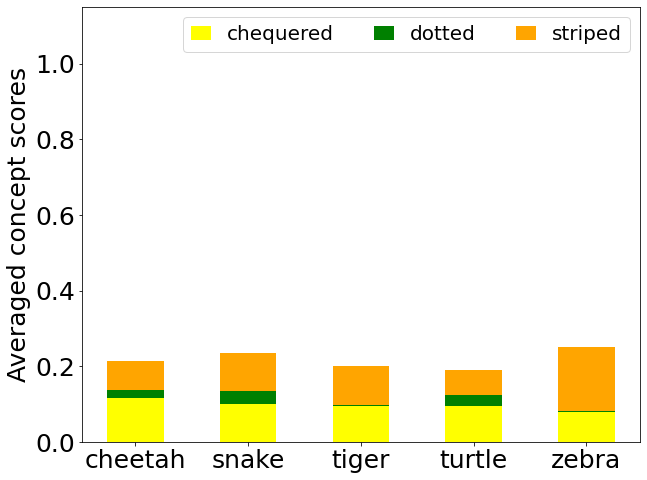

In [26]:
con_colors = ['yellow', 'green', 'orange']
fontsize = 25
fig, ax = plt.subplots(figsize=(10,8))
bottom = np.zeros(len(classes))
for i, (con, probs) in enumerate(probs_con_dict.items()):
    rects = plt.bar(classes, probs, width=0.5, label=con, bottom=bottom, color=con_colors[i])
    bottom += probs

# Add asterisks for zero-height bars
for rect, b in zip(rects, bottom):
   if b == 0:
       ax.text(rect.get_x() + rect.get_width() / 2,
               0.01,  # Adjust vertical position slightly
               '$\diamond$', ha='center', va='bottom', fontsize=fontsize+10, color='black')

plt.ylim(0.0, 1.15)
plt.legend(loc='upper right', fontsize=fontsize-5, ncol=len(concepts), handlelength=1.0)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.xticks(fontsize=fontsize); plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_imagenet_knn_stabcon_stacked.png', bbox_inches='tight')
plt.show()

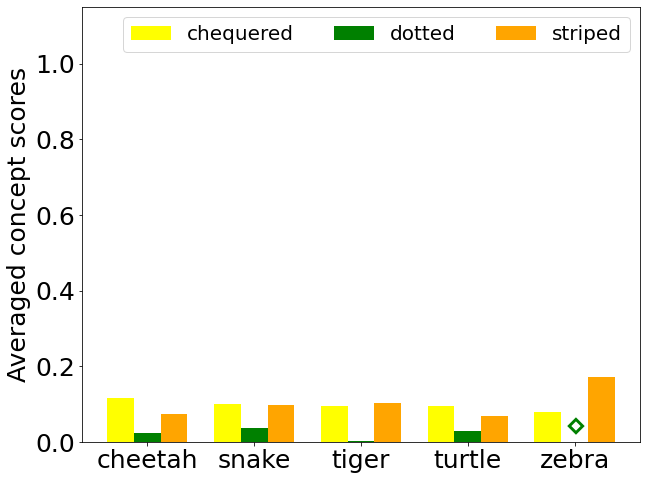

In [27]:
x = np.arange(len(classes))  # the label locations
width = 0.25  # the width of the bars
multiplier = 0
fontsize = 25
con_colors = ['yellow', 'green', 'orange']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(probs_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height < 1e-3:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '$\diamond$', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x + width, classes, fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.legend(loc='upper right', fontsize=fontsize-5, ncol=len(concepts))
plt.ylim(0.0, 1.15)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_imagenet_knn_stabcon.png', bbox_inches='tight')
plt.show()

##### Frequency of dominant prototypes

In [27]:
# Count how often each concept is predicted as dominant concept (knn_prob == max_prob)
sig_cls_dict = {}
for c in classes:
    cls_ind = np.where(y_true_img == classes.index(c))
    sig_cls_dict[c] = np.count_nonzero(knn_probs[cls_ind, :len(concepts)][0] ==
                                       np.tile(np.max(knn_probs[cls_ind, :len(concepts)][0], axis=1),
                                               (len(concepts),1)).T,
                                                axis=0) / len(cls_ind[0])
sig_cls_dict

{'cheetah': array([1., 1., 1.]),
 'snake': array([0.94594595, 1.        , 0.94594595]),
 'tiger': array([1., 1., 1.]),
 'turtle': array([1., 1., 1.]),
 'zebra': array([0.89583333, 0.89583333, 1.        ])}

In [28]:
# Invert dictionary (for plotting purposes)
sig_con_dict = {}
for c in concepts:
    sig_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        sig_con_dict[c][i] = sig_cls_dict[classes[i]][concepts.index(c)]
sig_con_dict

{'chequered': array([1.        , 0.94594595, 1.        , 1.        , 0.89583333]),
 'dotted': array([1.        , 1.        , 1.        , 1.        , 0.89583333]),
 'striped': array([1.        , 0.94594595, 1.        , 1.        , 1.        ])}

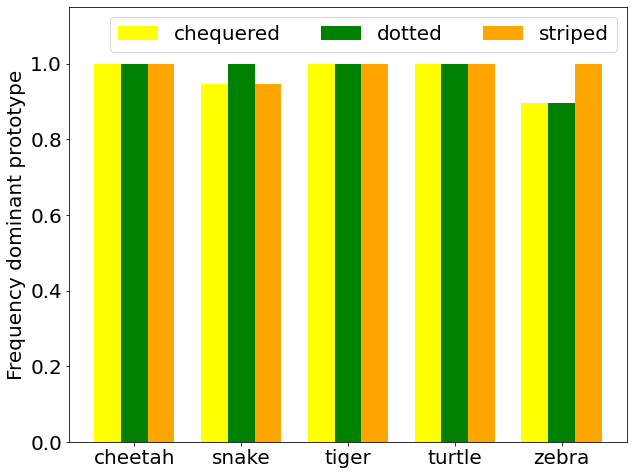

In [29]:
x = np.arange(len(classes))  # the label locations
width = 0.25  # the width of the bars
multiplier = 0
fontsize = 20
con_colors = ['yellow', 'green', 'orange']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(sig_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height == 0:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '*', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x + width, classes, fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.legend(loc='upper right', fontsize=fontsize, ncol=len(concepts))
plt.ylim(0.0, 1.15)
plt.ylabel('Frequency dominant prototype', fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav/imagenet_knn_freq_stabcon.png', bbox_inches='tight')
plt.show()

#### Multiple random partitions, one kNN per concept

In [30]:
# One-hot-encode the concepts
concept_basis = OneHotEncoder().fit_transform([[0], [1], [2]]).toarray()
lookup_cls_concepts = [concept_basis[1], # cheetah -> dotted
                       concept_basis[0], # snake -> chequered
                       concept_basis[2], # tiger -> striped
                       concept_basis[0], # turtle -> chequered
                       concept_basis[2]] # zebra -> striped

In [31]:
# Fit multiple kNNs for multiple random partitions of thre random set
k = 4 # optimal k found in ResNet_Cluster_Concepts_Optim_k.ipynb
num_parts = 30 # how often to randomly select subsets of the random set
knn_probs = np.zeros((len(test_activations), len(concepts))) # matrix of aggregated probs for every sample and every concept
for i in range(num_parts):

    # Select random indexes (starting after last concept img index)
    random_ids = np.random.choice( np.arange(len(y_true_con), len(con_rand_set)), 500,
                                   replace = False)

    # Fit a kNN on current partition for every concept
    for j in range(len(concepts)):
        # Overall index vector (concept indexes, then current random subset indexes)
        con_ids = np.where(np.asarray(y_true_con) == j)[0]
        con_rand_ids = np.concatenate( (con_ids, random_ids) )

        neigh = KNeighborsClassifier(n_neighbors=k)
        neigh.fit(res_con_rand.numpy()[con_rand_ids], y_true_con_rand[con_rand_ids])

        # Predict concepts for all test vectors
        knn_probs[:, j] += neigh.predict_proba(test_activations)[:, 0] # 2nd prob. is for random

# Average over number of random partitions
knn_probs /= num_parts
knn_probs

array([[0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   ],
       [0.

##### Offline metrics and mean scores per class

In [32]:
probs_cls_dict = {}
for c in classes:
    # Note: concept scores can add to more than 1 -> normalize by number pf concepts
    probs_cls_dict[c] = np.mean(knn_probs[np.where(y_true_img == classes.index(c))], axis=0)
    probs_cls_dict[c] /= len(concepts)

    # Get true concept(s) based on true class
    true_con = lookup_cls_concepts[classes.index(c)]
    # Compute cosine sim.
    cos_sim = cosine_similarity(true_con.reshape(1, -1), probs_cls_dict[c].reshape(1, -1))[0][0]
    # Compute binary cross entropy
    bce = log_loss(true_con, probs_cls_dict[c])

    print(c)
    print('Cosine Similarity:')
    print(cos_sim)
    print('BCE:')
    print(bce);
    print()

cheetah
Cosine Similarity:
0.0
BCE:
11.512925464970229

snake
Cosine Similarity:
0.0
BCE:
11.515109783410672

tiger
Cosine Similarity:
0.0
BCE:
11.512925464970229

turtle
Cosine Similarity:
0.0
BCE:
11.512925464970229

zebra
Cosine Similarity:
1.0
BCE:
1.6403410451355234



In [33]:
probs_cls_dict

{'cheetah': array([0., 0., 0.]),
 'snake': array([0.        , 0.00653153, 0.        ]),
 'tiger': array([0., 0., 0.]),
 'turtle': array([0., 0., 0.]),
 'zebra': array([0.        , 0.        , 0.00729167])}

In [34]:
probs_con_dict = {}
for c in concepts:
    probs_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        probs_con_dict[c][i] = probs_cls_dict[classes[i]][concepts.index(c)]
probs_con_dict

{'chequered': array([0., 0., 0., 0., 0.]),
 'dotted': array([0.        , 0.00653153, 0.        , 0.        , 0.        ]),
 'striped': array([0.        , 0.        , 0.        , 0.        , 0.00729167])}

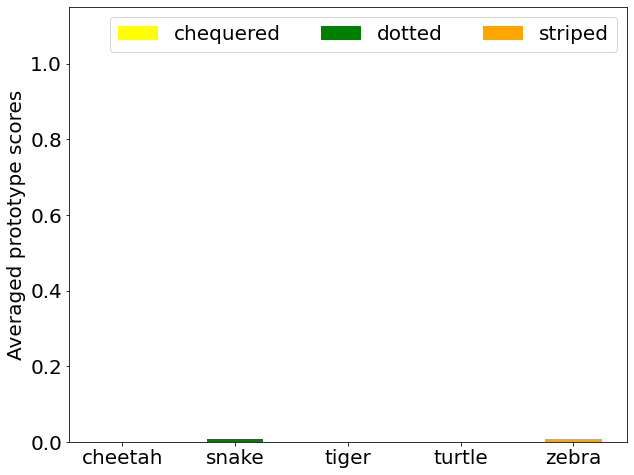

In [35]:
con_colors = ['yellow', 'green', 'orange']
fontsize = 20
plt.figure(figsize=(10,8))
bottom = np.zeros(len(classes))
for i, (con, probs) in enumerate(probs_con_dict.items()):
    plt.bar(classes, probs, width=0.5, label=con, bottom=bottom, color=con_colors[i])
    bottom += probs

plt.ylim(0.0, 1.15)
plt.legend(loc='upper right', fontsize=fontsize, ncol=len(concepts))
plt.ylabel('Averaged prototype scores', fontsize=fontsize)
plt.xticks(fontsize=fontsize); plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav/mean_imagenet_knn_stabcon_multilabel.png', bbox_inches='tight')
plt.show()

##### Frequency of dominant prototypes

In [36]:
# Count how often each concept is predicted as dominant concept (knn_prob == max_prob)
sig_cls_dict = {}
for c in classes:
    cls_ind = np.where(y_true_img == classes.index(c))
    sig_cls_dict[c] = np.count_nonzero(knn_probs[cls_ind, :len(concepts)][0] ==
                                       np.tile(np.max(knn_probs[cls_ind, :len(concepts)][0], axis=1),
                                               (len(concepts),1)).T,
                                                axis=0) / len(cls_ind[0])
sig_cls_dict

{'cheetah': array([1., 1., 1.]),
 'snake': array([0.94594595, 1.        , 0.94594595]),
 'tiger': array([1., 1., 1.]),
 'turtle': array([1., 1., 1.]),
 'zebra': array([0.89583333, 0.89583333, 1.        ])}

In [37]:
# Invert dictionary (for plotting purposes)
sig_con_dict = {}
for c in concepts:
    sig_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        sig_con_dict[c][i] = sig_cls_dict[classes[i]][concepts.index(c)]
sig_con_dict

{'chequered': array([1.        , 0.94594595, 1.        , 1.        , 0.89583333]),
 'dotted': array([1.        , 1.        , 1.        , 1.        , 0.89583333]),
 'striped': array([1.        , 0.94594595, 1.        , 1.        , 1.        ])}

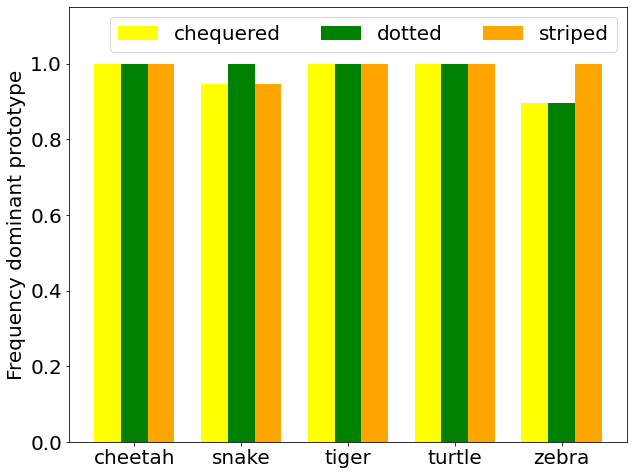

In [38]:
x = np.arange(len(classes))  # the label locations
width = 0.25  # the width of the bars
multiplier = 0
fontsize = 20
con_colors = ['yellow', 'green', 'orange']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(sig_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height == 0:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '*', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x + width, classes, fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.legend(loc='upper right', fontsize=fontsize, ncol=len(concepts))
plt.ylim(0.0, 1.15)
plt.ylabel('Frequency dominant prototype', fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav/imagenet_knn_freq_stabcon_multilabel.png', bbox_inches='tight')
plt.show()